# Week 3 – Statistical Analysis and Hypothesis Testing
**Dataset:** cleaned Telco Customer Churn data (`data/processed/telco_churn_clean.csv`, 7,043 customers)
**Author:** Anish Goyal

In Weeks 1 and 2 I *saw* patterns in charts. Patterns in a sample can appear by chance, so this week I test them formally.
For each idea I write a null and alternative hypothesis, pick a test whose assumptions fit the data, and report the
p-value, an effect size and a confidence interval.

| # | Business question | Test |
|---|---|---|
| H1 | Do customers who churn pay more per month? | Welch's t-test (+ Mann–Whitney U) |
| H2 | Is contract type associated with churn? | Chi-square test of independence |
| H3 | Do monthly charges differ by payment method? | One-way ANOVA / Welch ANOVA + post-hoc tests |
| H4 | Do internet customers with Tech Support churn less? | Two-proportion z-test + logistic regression |
| H5 (control) | Is gender associated with churn? | Chi-square test |

**Significance level.** Five hypotheses are tested, so I use a Bonferroni-corrected level of **α = 0.05 / 5 = 0.01**
to keep the overall chance of a false positive at about 5%.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_confint

df = pd.read_csv("../data/processed/telco_churn_clean.csv")
FIG = Path("../reports/figures/week3")
FIG.mkdir(parents=True, exist_ok=True)

ALPHA = 0.05 / 5
ORANGE, BLUE, GREY, DARK = "#E8743B", "#4C78A8", "#B0B0B0", "#333333"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})

results = []   # collect one summary row per hypothesis
print(df.shape, "| alpha =", ALPHA)

(7043, 23) | alpha = 0.01


## H1 – Do churned customers pay higher monthly charges?
- **H₀:** mean monthly charge of churned customers = mean of retained customers (μ_churn = μ_stay)
- **H₁:** the means are different (μ_churn ≠ μ_stay), two-sided

**Choosing the test.** Two independent groups and a numeric outcome → two-sample t-test. Before running it I check the assumptions.

In [2]:
churn = df.loc[df["Churn"] == "Yes", "MonthlyCharges"]
stay = df.loc[df["Churn"] == "No", "MonthlyCharges"]

summary = pd.DataFrame({"n": [len(churn), len(stay)],
                        "mean": [churn.mean(), stay.mean()],
                        "median": [churn.median(), stay.median()],
                        "std": [churn.std(), stay.std()],
                        "skew": [churn.skew(), stay.skew()]}, index=["Churned", "Stayed"]).round(2)
summary

,n,mean,median,std,skew
Churned,1869,74.44,79.65,24.67,-0.73
Stayed,5174,61.27,64.43,31.09,-0.03


In [3]:
lev = stats.levene(churn, stay)
print(f"Levene test for equal variances: W = {lev.statistic:.1f}, p = {lev.pvalue:.2e}")

Levene test for equal variances: W = 361.8, p = 1.03e-78


**Assumption check.**
- *Equal variances:* Levene's test rejects equal variances (p ≈ 10⁻⁷⁸), so the classic Student t-test is not appropriate. I use **Welch's t-test**, which does not assume equal variances.
- *Normality:* the charges are not normal (the "stayed" group has a big spike of cheap phone-only plans). With n = 1,869 and 5,174 the Central Limit Theorem makes the sampling distribution of the mean approximately normal, so the t-test is still valid. As a robustness check I also run the **Mann–Whitney U** test, which needs no normality assumption.

In [4]:
t = stats.ttest_ind(churn, stay, equal_var=False)
ci = t.confidence_interval(confidence_level=0.95)
diff = churn.mean() - stay.mean()

pooled_sd = np.sqrt(((len(churn) - 1) * churn.var() + (len(stay) - 1) * stay.var()) / (len(churn) + len(stay) - 2))
cohens_d = diff / pooled_sd

mw = stats.mannwhitneyu(churn, stay, alternative="two-sided")
rank_biserial = 2 * mw.statistic / (len(churn) * len(stay)) - 1

print(f"Welch t = {t.statistic:.2f}, df = {t.df:.0f}, p = {t.pvalue:.2e}")
print(f"Mean difference = ${diff:.2f}  (95% CI ${ci.low:.2f} to ${ci.high:.2f})")
print(f"Cohen's d = {cohens_d:.2f}")
print(f"Mann-Whitney U = {mw.statistic:,.0f}, p = {mw.pvalue:.2e}, rank-biserial r = {rank_biserial:.2f}")

results.append(["H1", "Churned customers pay different monthly charges", "Welch t-test",
                f"t = {t.statistic:.2f}", t.pvalue, f"d = {cohens_d:.2f}", "Reject H0" if t.pvalue < ALPHA else "Fail to reject H0"])

Welch t = 18.41, df = 4136, p = 8.59e-73
Mean difference = $13.18  (95% CI $11.77 to $14.58)
Cohen's d = 0.45
Mann-Whitney U = 6,003,126, p = 3.31e-54, rank-biserial r = 0.24


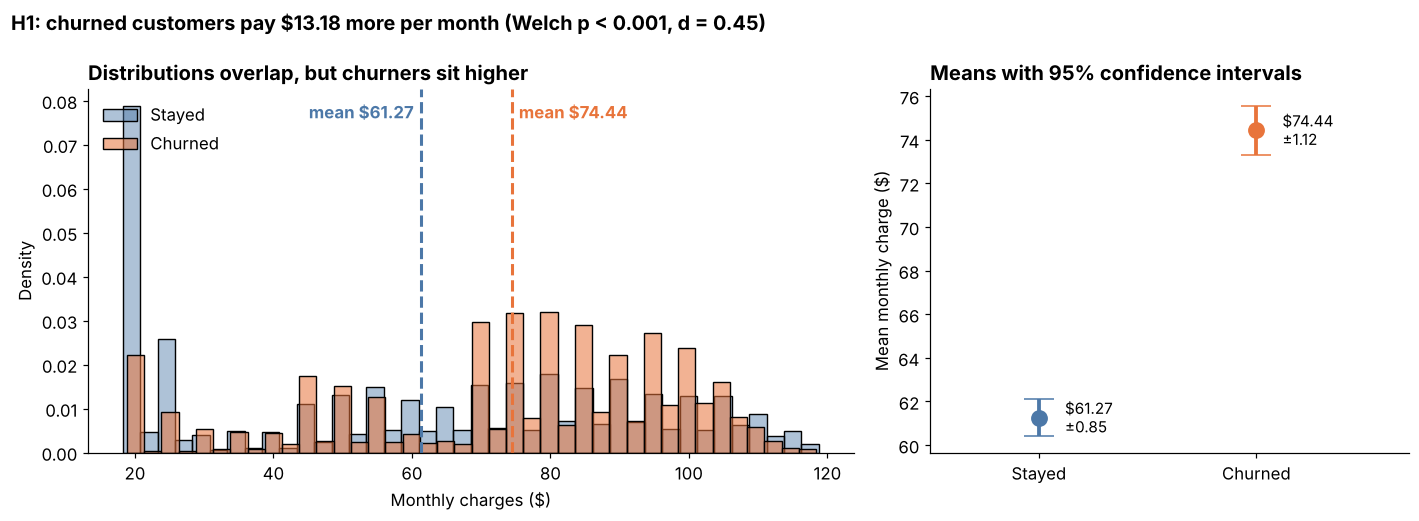

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
sns.histplot(stay, bins=40, stat="density", color=BLUE, alpha=0.45, label="Stayed", ax=ax)
sns.histplot(churn, bins=40, stat="density", color=ORANGE, alpha=0.55, label="Churned", ax=ax)
ax.axvline(stay.mean(), color=BLUE, ls="--", lw=2); ax.axvline(churn.mean(), color=ORANGE, ls="--", lw=2)
ax.text(stay.mean() - 1, ax.get_ylim()[1] * 0.92, f"mean ${stay.mean():.2f}", ha="right", color=BLUE, fontweight="bold")
ax.text(churn.mean() + 1, ax.get_ylim()[1] * 0.92, f"mean ${churn.mean():.2f}", color=ORANGE, fontweight="bold")
ax.set_xlabel("Monthly charges ($)"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Distributions overlap, but churners sit higher")

ax = axes[1]
for i, (name, s, c) in enumerate([("Stayed", stay, BLUE), ("Churned", churn, ORANGE)]):
    m = s.mean(); se = s.std() / np.sqrt(len(s)); h = stats.t.ppf(0.975, len(s) - 1) * se
    ax.errorbar(i, m, yerr=h, fmt="o", color=c, capsize=10, markersize=10, lw=2.5)
    ax.text(i + 0.12, m, f"${m:.2f}\n±{h:.2f}", va="center", fontsize=10)
ax.set_xticks([0, 1], ["Stayed", "Churned"]); ax.set_xlim(-0.5, 1.7)
ax.set_ylabel("Mean monthly charge ($)")
ax.set_title("Means with 95% confidence intervals")
fig.suptitle(f"H1: churned customers pay ${diff:.2f} more per month (Welch p < 0.001, d = {cohens_d:.2f})",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "h1_monthly_charges.png", bbox_inches="tight")
plt.show()

**Interpretation.** p is far below 0.01, so I **reject H₀**. Churned customers pay on average **$13.18 more per month**,
and the 95% confidence interval ($11.77 to $14.58) tells us the true difference in the population is very likely in that
range – it does not include 0. Cohen's d ≈ 0.45 is a *small-to-medium* effect: price matters, but it does not explain churn
on its own. The Mann–Whitney test agrees (p ≈ 10⁻⁵⁴), so the result does not depend on the normality assumption.

## H2 – Is contract type associated with churn?
- **H₀:** contract type and churn are independent
- **H₁:** contract type and churn are associated

**Choosing the test.** Two categorical variables → **chi-square test of independence**. Assumption: every expected cell count should be ≥ 5.

In [6]:
ct = pd.crosstab(df["Contract"], df["Churn"])
chi2, p, dof, expected = stats.chi2_contingency(ct)
expected = pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(1)

n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print("Observed:\n", ct, "\n\nExpected under H0:\n", expected)
print(f"\nSmallest expected count = {expected.values.min():.1f}  (assumption met: all >= 5)")
print(f"Chi-square = {chi2:.1f}, df = {dof}, p = {p:.2e}, Cramer's V = {cramers_v:.2f}")

results.append(["H2", "Contract type is associated with churn", "Chi-square test",
                f"χ² = {chi2:.1f}, df = {dof}", p, f"V = {cramers_v:.2f}", "Reject H0" if p < ALPHA else "Fail to reject H0"])

Observed:
 Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48 

Expected under H0:
 Churn               No     Yes
Contract                      
Month-to-month  2846.7  1028.3
One year        1082.1   390.9
Two year        1245.2   449.8

Smallest expected count = 390.9  (assumption met: all >= 5)
Chi-square = 1184.6, df = 2, p = 5.86e-258, Cramer's V = 0.41


The chi-square test says *whether* there is an association. To see *where* it comes from I look at the
**standardized residuals** (observed − expected) / √expected. Values beyond ±2 mean the cell is clearly different from what independence predicts.

In [7]:
std_resid = (ct - expected) / np.sqrt(expected)
rates = df.groupby("Contract")["ChurnFlag"].agg(["sum", "count"])
ci_low, ci_high = proportion_confint(rates["sum"], rates["count"], method="wilson")
rates["rate"] = rates["sum"] / rates["count"]; rates["low"] = ci_low; rates["high"] = ci_high
print(std_resid.round(1)); rates.round(3)

Churn             No   Yes
Contract                  
Month-to-month -11.7  19.5
One year         6.8 -11.4
Two year        11.4 -18.9


,sum,count,rate,low,high
Contract,,,,,
Month-to-month,1655,3875,0.427,0.412,0.443
One year,166,1473,0.113,0.098,0.130
Two year,48,1695,0.028,0.021,0.037


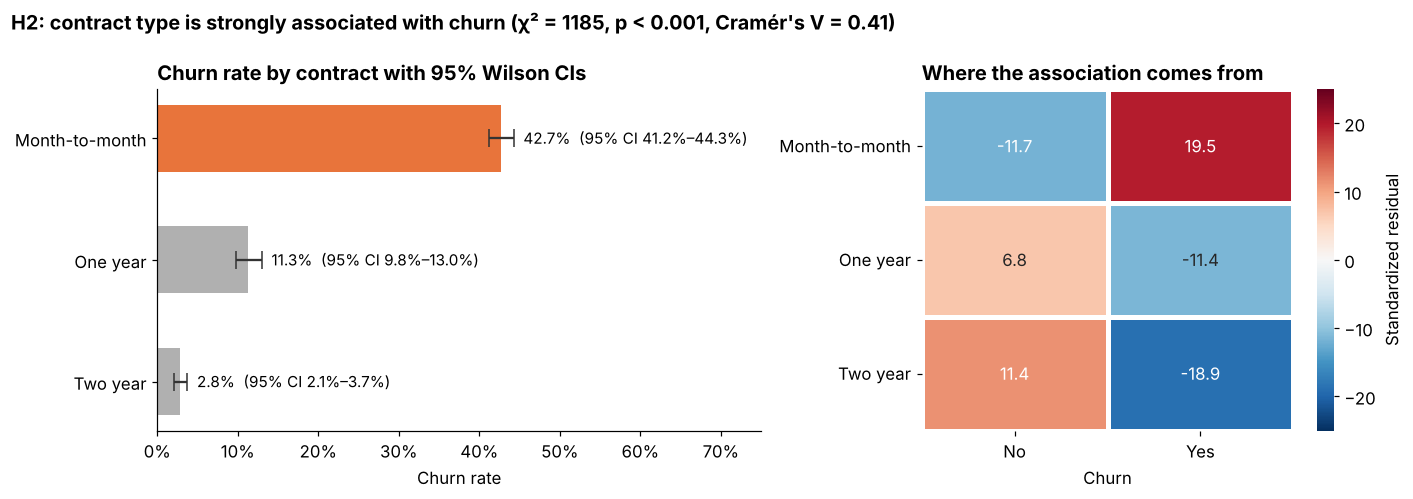

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
y = np.arange(len(rates))
ax.barh(y, rates["rate"], color=[ORANGE, GREY, GREY], height=0.55)
ax.errorbar(rates["rate"], y, xerr=[rates["rate"] - rates["low"], rates["high"] - rates["rate"]],
            fmt="none", ecolor=DARK, capsize=6, lw=1.5)
for i, (r, lo, hi) in enumerate(rates[["rate", "low", "high"]].values):
    ax.text(hi + 0.012, i, f"{r:.1%}  (95% CI {lo:.1%}–{hi:.1%})", va="center", fontsize=10)
ax.set_yticks(y, rates.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(0, 0.75)
ax.set_xlabel("Churn rate")
ax.set_title("Churn rate by contract with 95% Wilson CIs")

ax = axes[1]
sns.heatmap(std_resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-25, vmax=25,
            linewidths=2, linecolor="white", cbar_kws={"label": "Standardized residual"}, ax=ax)
ax.set_xlabel("Churn"); ax.set_ylabel(""); ax.tick_params(axis="y", rotation=0)
ax.set_title("Where the association comes from")
fig.suptitle(f"H2: contract type is strongly associated with churn (χ² = {chi2:.0f}, p < 0.001, Cramér's V = {cramers_v:.2f})",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "h2_contract_chisquare.png", bbox_inches="tight")
plt.show()

**Interpretation.** χ² = 1,184.6 with 2 degrees of freedom gives p ≈ 10⁻²⁵⁸, so I **reject H₀**: contract type and churn are
not independent. Cramér's V = 0.41 is a **strong** association for survey/customer data. The residuals show the effect is driven by
far *more* churners than expected on month-to-month plans (+19.5) and far *fewer* than expected on two-year plans (−18.9).
The confidence intervals do not overlap at all, so the gap between contract types is not a sampling accident.

## H3 – Do monthly charges differ across payment methods?
In Week 2, electronic-check customers stood out as high risk. One explanation could be that they are simply on more
expensive plans. Before blaming the payment method, I test whether the groups actually pay different amounts.

- **H₀:** mean monthly charge is the same for all four payment methods (μ₁ = μ₂ = μ₃ = μ₄)
- **H₁:** at least one payment method has a different mean

**Choosing the test.** One numeric outcome, four independent groups → **one-way ANOVA**.

In [9]:
order = ["Electronic check", "Bank transfer (automatic)", "Credit card (automatic)", "Mailed check"]
groups = [df.loc[df["PaymentMethod"] == g, "MonthlyCharges"] for g in order]
print(df.groupby("PaymentMethod")["MonthlyCharges"].agg(["count", "mean", "std"]).loc[order].round(2))

lev3 = stats.levene(*groups)
f_classic = stats.f_oneway(*groups)
welch = anova_oneway(df["MonthlyCharges"], df["PaymentMethod"], use_var="unequal")
kw = stats.kruskal(*groups)

ss_between = sum(len(g) * (g.mean() - df["MonthlyCharges"].mean()) ** 2 for g in groups)
ss_total = ((df["MonthlyCharges"] - df["MonthlyCharges"].mean()) ** 2).sum()
eta_sq = ss_between / ss_total

print(f"\nLevene: W = {lev3.statistic:.1f}, p = {lev3.pvalue:.2e}  -> variances are unequal")
print(f"Classic ANOVA: F = {f_classic.statistic:.1f}, p = {f_classic.pvalue:.2e}")
print(f"Welch ANOVA:   F = {welch.statistic:.1f}, p = {welch.pvalue:.2e}")
print(f"Kruskal-Wallis: H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}")
print(f"Eta squared = {eta_sq:.3f}")

results.append(["H3", "Monthly charges differ by payment method", "Welch ANOVA",
                f"F = {welch.statistic:.1f}", welch.pvalue, f"η² = {eta_sq:.2f}", "Reject H0" if welch.pvalue < ALPHA else "Fail to reject H0"])

                           count   mean    std
PaymentMethod                                 
Electronic check            2365  76.26  24.05
Bank transfer (automatic)   1544  67.19  30.56
Credit card (automatic)     1522  66.51  30.61
Mailed check                1612  43.92  26.31

Levene: W = 81.3, p = 1.09e-51  -> variances are unequal
Classic ANOVA: F = 450.3, p = 1.18e-267
Welch ANOVA:   F = 520.9, p = 9.55e-281
Kruskal-Wallis: H = 1103.3, p = 7.01e-239
Eta squared = 0.161


**Assumption check.** Levene's test shows unequal variances (electronic-check customers have a narrower spread), so I report
**Welch's ANOVA** as the main result; the classic ANOVA and the non-parametric Kruskal–Wallis test are shown as robustness checks. All three agree.

ANOVA only says *some* groups differ. To find *which* pairs differ I run pairwise Welch t-tests with the **Holm correction**
for multiple comparisons (six pairs), and Tukey's HSD for comparison.

In [10]:
pairs = []
for i in range(len(order)):
    for j in range(i + 1, len(order)):
        a, b = groups[i], groups[j]
        tt = stats.ttest_ind(a, b, equal_var=False)
        ci_ = tt.confidence_interval()
        pairs.append([order[i], order[j], a.mean() - b.mean(), ci_.low, ci_.high, tt.pvalue])
pairs = pd.DataFrame(pairs, columns=["group_1", "group_2", "mean_diff", "ci_low", "ci_high", "p_raw"])
pairs["p_holm"] = multipletests(pairs["p_raw"], method="holm")[1]
pairs["significant"] = pairs["p_holm"] < ALPHA
pairs.round(4)

,group_1,group_2,mean_diff,ci_low,ci_high,p_raw,p_holm,significant
0,Electronic check,Bank transfer (automatic),9.0632,7.2561,10.8702,0.0000,0.0000,True
1,Electronic check,Credit card (automatic),9.7434,7.9246,11.5622,0.0000,0.0000,True
2,Electronic check,Mailed check,32.3388,30.7288,33.9487,0.0000,0.0000,True
3,Bank transfer (automatic),Credit card (automatic),0.6803,-1.4858,2.8463,0.5381,0.5381,False
4,Bank transfer (automatic),Mailed check,23.2756,21.2816,25.2696,0.0000,0.0000,True
5,Credit card (automatic),Mailed check,22.5953,20.5907,24.6000,0.0000,0.0000,True


In [11]:
print(pairwise_tukeyhsd(df["MonthlyCharges"], df["PaymentMethod"], alpha=ALPHA))

                   Multiple Comparison of Means - Tukey HSD, FWER=0.01                    
          group1                   group2         meandiff p-adj   lower    upper   reject
------------------------------------------------------------------------------------------
Bank transfer (automatic) Credit card (automatic)  -0.6803 0.9035  -3.7814   2.4208  False
Bank transfer (automatic)        Electronic check   9.0632    0.0   6.2541  11.8722   True
Bank transfer (automatic)            Mailed check -23.2756    0.0 -26.3328 -20.2184   True
  Credit card (automatic)        Electronic check   9.7434    0.0   6.9222  12.5647   True
  Credit card (automatic)            Mailed check -22.5953    0.0 -25.6638 -19.5269   True
         Electronic check            Mailed check -32.3388    0.0 -35.1117 -29.5658   True
------------------------------------------------------------------------------------------


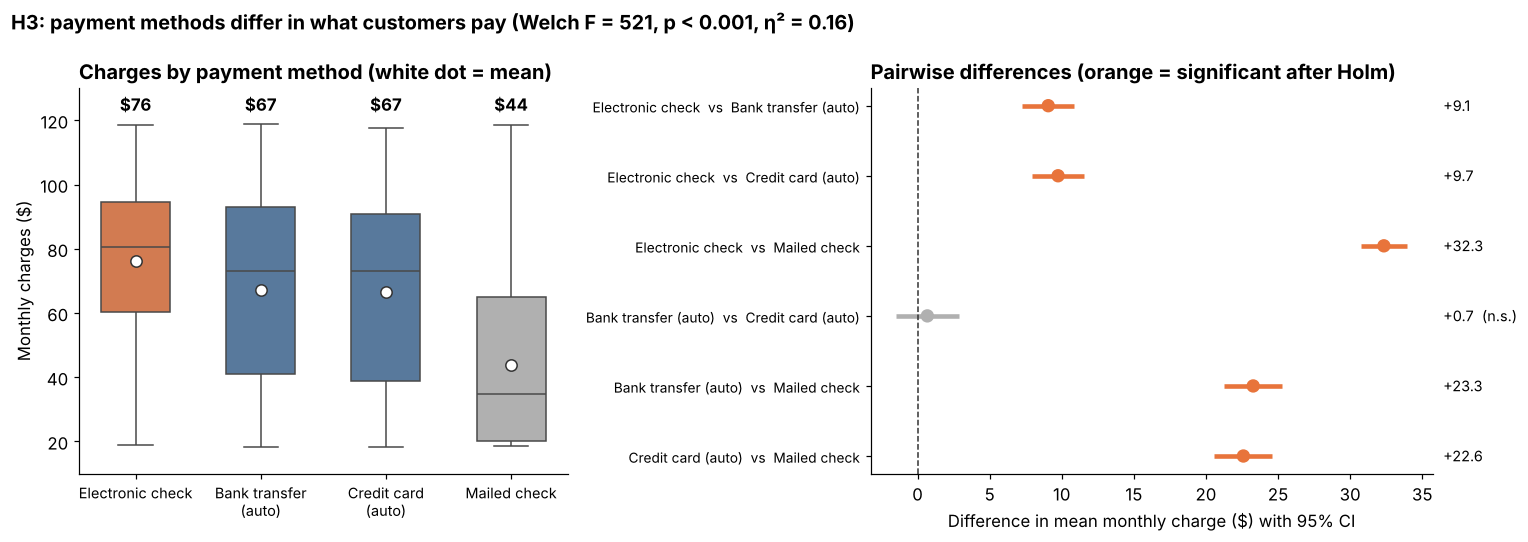

In [12]:
short = {"Electronic check": "Electronic check", "Bank transfer (automatic)": "Bank transfer (auto)",
         "Credit card (automatic)": "Credit card (auto)", "Mailed check": "Mailed check"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
pal = [ORANGE, BLUE, BLUE, GREY]
sns.boxplot(data=df, x="PaymentMethod", y="MonthlyCharges", order=order, hue="PaymentMethod", hue_order=order,
            palette=pal, legend=False, width=0.55, fliersize=2, ax=ax)
means = [g.mean() for g in groups]
ax.scatter(range(4), means, color="white", edgecolor=DARK, zorder=5, s=55)
for i, m in enumerate(means):
    ax.text(i, 123, f"${m:.0f}", ha="center", fontweight="bold")
ax.set_xticks(range(4), [short[o].replace(" (", "\n(") for o in order], fontsize=9.5)
ax.set_xlabel(""); ax.set_ylabel("Monthly charges ($)"); ax.set_ylim(10, 130)
ax.set_title("Charges by payment method (white dot = mean)")

ax = axes[1]
lab = pairs["group_1"].map(short) + "  vs  " + pairs["group_2"].map(short)
yy = np.arange(len(pairs))[::-1]
cols = [ORANGE if s else GREY for s in pairs["significant"]]
ax.hlines(yy, pairs["ci_low"], pairs["ci_high"], color=cols, lw=3)
ax.scatter(pairs["mean_diff"], yy, color=cols, s=60, zorder=3)
ax.axvline(0, color=DARK, lw=1, ls="--")
for y_, (d, s) in zip(yy, pairs[["mean_diff", "significant"]].values):
    ax.text(pairs["ci_high"].max() + 2.5, y_, f"{d:+.1f}" + ("" if s else "  (n.s.)"), va="center", fontsize=9.5)
ax.set_yticks(yy, lab, fontsize=9)
ax.set_xlabel("Difference in mean monthly charge ($) with 95% CI")
ax.set_title("Pairwise differences (orange = significant after Holm)")
fig.suptitle(f"H3: payment methods differ in what customers pay (Welch F = {welch.statistic:.0f}, p < 0.001, η² = {eta_sq:.2f})",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "h3_payment_anova.png", bbox_inches="tight")
plt.show()

**Interpretation.** Welch's F ≈ 521 with p ≈ 10⁻²⁸¹, so I **reject H₀**: average charges differ by payment method.
η² = 0.16 means payment method explains about **16% of the variation** in monthly charges, a large effect.
Five of the six pairs differ significantly; the only exception is **bank transfer vs credit card** (difference $0.68, not significant),
which makes sense because both are automatic payments. Electronic-check users pay about **$9–10 more** than automatic payers and
**$32 more** than mailed-check users.

**Why this matters:** part of the high churn among electronic-check users may come from them being on pricier (often fiber)
plans, not from the payment method itself. This is a confounding variable to control for in modelling.

## H4 – Do internet customers with Tech Support churn less?
Week 2 showed a big gap in churn between customers with and without Tech Support. I restrict this test to **internet
customers only**, because customers without internet cannot buy Tech Support at all.

- **H₀:** churn rate with Tech Support = churn rate without (p_with = p_without)
- **H₁:** churn rate with Tech Support is **lower** (p_with < p_without), one-sided because the business question has a direction

**Choosing the test.** Comparing two proportions from independent groups → **two-proportion z-test**. Assumption: at least
10 successes and 10 failures in each group (easily met here).

In [13]:
net = df[df["InternetService"] != "No"].copy()
tab = net.groupby("TechSupport")["ChurnFlag"].agg(churned="sum", customers="count")
tab["rate"] = tab["churned"] / tab["customers"]
print(tab.round(3))

z, p_one = proportions_ztest(count=[tab.loc["Yes", "churned"], tab.loc["No", "churned"]],
                             nobs=[tab.loc["Yes", "customers"], tab.loc["No", "customers"]],
                             alternative="smaller")
diff_low, diff_high = confint_proportions_2indep(tab.loc["No", "churned"], tab.loc["No", "customers"],
                                                 tab.loc["Yes", "churned"], tab.loc["Yes", "customers"])
rr = tab.loc["Yes", "rate"] / tab.loc["No", "rate"]
print(f"\nz = {z:.2f}, one-sided p = {p_one:.2e}")
print(f"Difference (No - Yes) = {tab.loc['No','rate'] - tab.loc['Yes','rate']:.1%}  (95% CI {diff_low:.1%} to {diff_high:.1%})")
print(f"Relative risk = {rr:.2f}")

results.append(["H4", "Tech Support customers churn less (internet users)", "Two-proportion z-test",
                f"z = {z:.2f}", p_one, f"RR = {rr:.2f}", "Reject H0" if p_one < ALPHA else "Fail to reject H0"])

             churned  customers   rate
TechSupport                           
No              1446       3473  0.416
Yes              310       2044  0.152

z = -20.38, one-sided p = 1.18e-92
Difference (No - Yes) = 26.5%  (95% CI 24.2% to 28.7%)
Relative risk = 0.36


**Is it really Tech Support, or something else?** Customers who buy Tech Support might also be on longer contracts,
which we already know reduces churn. To check this, I fit a **logistic regression** that controls for contract type,
tenure and monthly charges at the same time. If the Tech Support effect survives, it is not just a side effect of those variables.

In [14]:
logit = smf.logit("ChurnFlag ~ C(TechSupport) + C(Contract) + tenure + MonthlyCharges", data=net).fit(disp=0)
or_table = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": np.exp(logit.conf_int()[0]),
                         "ci_high": np.exp(logit.conf_int()[1]), "p_value": logit.pvalues}).drop("Intercept")
print(logit.summary().tables[1])
or_table.round(4)

                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -1.2482      0.125    -10.008      0.000      -1.493      -1.004
C(TechSupport)[T.Yes]      -0.6552      0.082     -8.013      0.000      -0.816      -0.495
C(Contract)[T.One year]    -0.8439      0.107     -7.870      0.000      -1.054      -0.634
C(Contract)[T.Two year]    -1.6274      0.181     -8.976      0.000      -1.983      -1.272
tenure                     -0.0342      0.002    -16.303      0.000      -0.038      -0.030
MonthlyCharges              0.0254      0.002     14.488      0.000       0.022       0.029


,odds_ratio,ci_low,ci_high,p_value
C(TechSupport)[T.Yes],0.5193,0.4424,0.6096,0.0
C(Contract)[T.One year],0.4300,0.3485,0.5306,0.0
C(Contract)[T.Two year],0.1964,0.1377,0.2803,0.0
tenure,0.9664,0.9624,0.9704,0.0
MonthlyCharges,1.0257,1.0222,1.0293,0.0


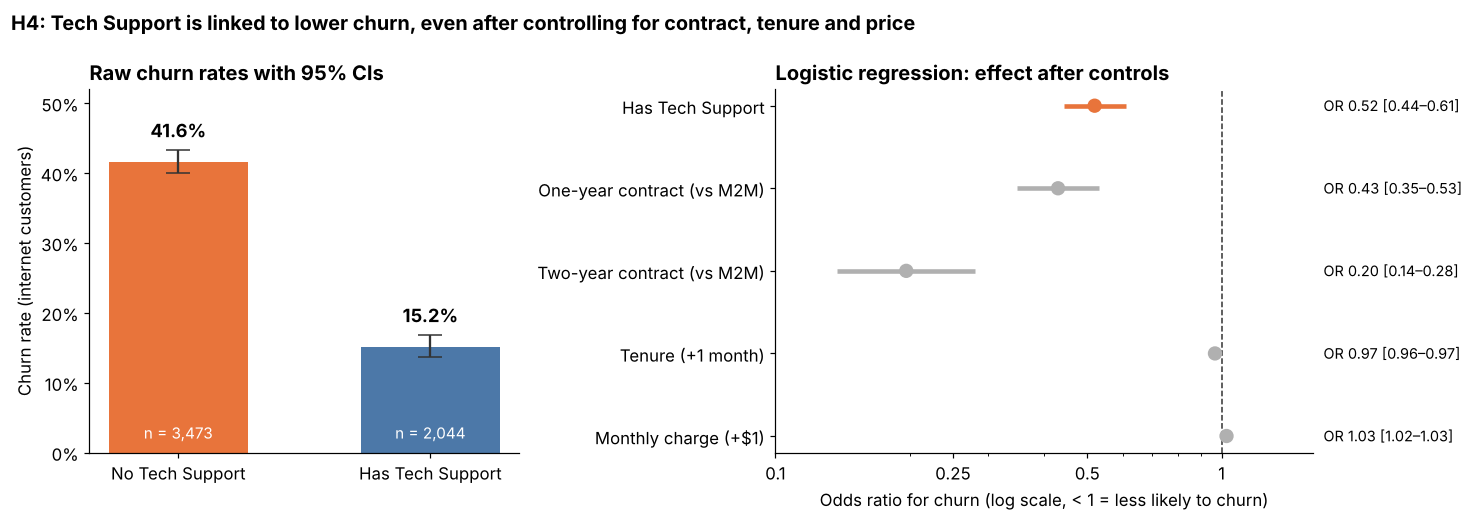

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
lo, hi = proportion_confint(tab["churned"], tab["customers"], method="wilson")
xs = [0, 1]; labels = ["No Tech Support", "Has Tech Support"]; vals = [tab.loc["No", "rate"], tab.loc["Yes", "rate"]]
errs = [[vals[0] - lo["No"], vals[1] - lo["Yes"]], [hi["No"] - vals[0], hi["Yes"] - vals[1]]]
ax.bar(xs, vals, color=[ORANGE, BLUE], width=0.55)
ax.errorbar(xs, vals, yerr=errs, fmt="none", ecolor=DARK, capsize=8, lw=1.5)
for x_, v, n_ in zip(xs, vals, [tab.loc["No", "customers"], tab.loc["Yes", "customers"]]):
    ax.text(x_, v + 0.035, f"{v:.1%}", ha="center", fontweight="bold", fontsize=12)
    ax.text(x_, 0.02, f"n = {n_:,}", ha="center", color="white", fontsize=10)
ax.set_xticks(xs, labels); ax.set_ylim(0, 0.52)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylabel("Churn rate (internet customers)")
ax.set_title("Raw churn rates with 95% CIs")

ax = axes[1]
nice = {"C(TechSupport)[T.Yes]": "Has Tech Support", "C(Contract)[T.One year]": "One-year contract (vs M2M)",
        "C(Contract)[T.Two year]": "Two-year contract (vs M2M)", "tenure": "Tenure (+1 month)",
        "MonthlyCharges": "Monthly charge (+$1)"}
ot = or_table.rename(index=nice).iloc[::-1]
yy = np.arange(len(ot))
cols = [ORANGE if i == "Has Tech Support" else GREY for i in ot.index]
ax.hlines(yy, ot["ci_low"], ot["ci_high"], color=cols, lw=3)
ax.scatter(ot["odds_ratio"], yy, color=cols, s=70, zorder=3)
ax.axvline(1, color=DARK, ls="--", lw=1)
for y_, (o, l, h) in zip(yy, ot[["odds_ratio", "ci_low", "ci_high"]].values):
    ax.text(1.02, y_, f"OR {o:.2f} [{l:.2f}–{h:.2f}]", va="center", fontsize=9.5, transform=ax.get_yaxis_transform())
ax.set_xscale("log"); ax.set_xlim(0.1, 1.6)
ax.set_xticks([0.1, 0.25, 0.5, 1], ["0.1", "0.25", "0.5", "1"])
ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_yticks(yy, ot.index)
ax.set_xlabel("Odds ratio for churn (log scale, < 1 = less likely to churn)")
ax.set_title("Logistic regression: effect after controls")
fig.suptitle(f"H4: Tech Support is linked to lower churn, even after controlling for contract, tenure and price",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "h4_techsupport.png", bbox_inches="tight")
plt.show()

**Interpretation.** Internet customers without Tech Support churn at **41.6%** against **15.2%** with it. The one-sided
z-test gives p ≈ 10⁻⁹², so I **reject H₀**. The difference is **26.5 percentage points** (95% CI 24.2 to 28.7 points),
and customers with Tech Support have about **0.36 times** the churn risk (relative risk).

In the logistic regression, the odds ratio for Tech Support is **0.52 (95% CI 0.44–0.61)**: holding contract, tenure and
monthly charge constant, customers with Tech Support have roughly **half the odds** of churning. The effect shrinks compared
with the raw numbers (part of it was really the contract effect), but it remains strong and significant. This is still
observational data, so it shows a robust association, not proof that adding Tech Support *causes* customers to stay.

## H5 (control) – Is gender associated with churn?
A good analysis should also show when there is **no** effect. Week 1 suggested gender does not matter; here I test it formally.
- **H₀:** gender and churn are independent
- **H₁:** gender and churn are associated

In [16]:
ct_g = pd.crosstab(df["gender"], df["Churn"])
chi2_g, p_g, dof_g, exp_g = stats.chi2_contingency(ct_g)
v_g = np.sqrt(chi2_g / (ct_g.values.sum() * (min(ct_g.shape) - 1)))
rates_g = df.groupby("gender")["ChurnFlag"].mean()
print(ct_g); print(rates_g.round(4))
print(f"\nChi-square = {chi2_g:.3f}, df = {dof_g}, p = {p_g:.3f}, Cramer's V = {v_g:.3f}")
results.append(["H5", "Gender is associated with churn (control)", "Chi-square test",
                f"χ² = {chi2_g:.2f}, df = {dof_g}", p_g, f"V = {v_g:.3f}", "Reject H0" if p_g < ALPHA else "Fail to reject H0"])

Churn     No  Yes
gender           
Female  2549  939
Male    2625  930
gender
Female    0.2692
Male      0.2616
Name: ChurnFlag, dtype: float64

Chi-square = 0.484, df = 1, p = 0.487, Cramer's V = 0.008


**Interpretation.** p = 0.487 is far above 0.01 (and above 0.05), so I **fail to reject H₀**. Churn is 26.9% for women and
26.2% for men, and Cramér's V ≈ 0.01 shows essentially no association. Note that "fail to reject" does not prove the rates are
exactly equal – only that the data gives no evidence of a difference. This result is useful in its own right: retention
campaigns do not need to be targeted by gender.

## Summary of all tests

In [17]:
summary = pd.DataFrame(results, columns=["Hypothesis", "Claim tested (H1)", "Test", "Statistic", "p-value", "Effect size", "Decision (α = 0.01)"])
summary["p-value"] = summary["p-value"].map(lambda v: "< 0.001" if v < 0.001 else f"{v:.3f}")
summary

,Hypothesis,Claim tested (H1),Test,Statistic,p-value,Effect size,Decision (α = 0.01)
0,H1,Churned customers pay different monthly charges,Welch t-test,t = 18.41,< 0.001,d = 0.45,Reject H0
1,H2,Contract type is associated with churn,Chi-square test,"χ² = 1184.6, df = 2",< 0.001,V = 0.41,Reject H0
2,H3,Monthly charges differ by payment method,Welch ANOVA,F = 520.9,< 0.001,η² = 0.16,Reject H0
3,H4,Tech Support customers churn less (internet us...,Two-proportion z-test,z = -20.38,< 0.001,RR = 0.36,Reject H0
4,H5,Gender is associated with churn (control),Chi-square test,"χ² = 0.48, df = 1",0.487,V = 0.008,Fail to reject H0


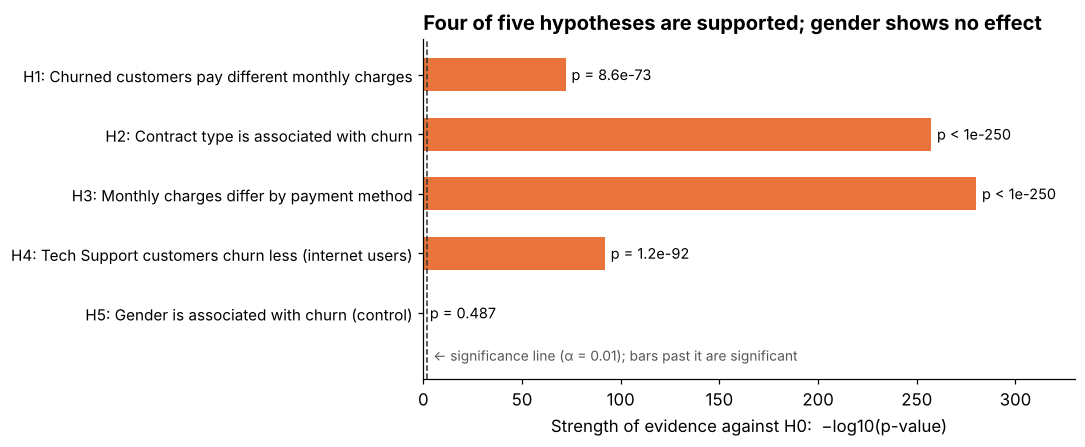

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.2))
raw_p = [r[4] for r in results]
logp = [-np.log10(max(pv, 1e-300)) for pv in raw_p]
names = [f"{r[0]}: {r[1]}" for r in results]
cols = [ORANGE if pv < ALPHA else GREY for pv in raw_p]
yy = np.arange(len(names))[::-1]
ax.barh(yy, logp, color=cols, height=0.55)
ax.axvline(-np.log10(ALPHA), color=DARK, ls="--", lw=1)
ax.set_ylim(-1.1, len(names) - 0.4)
ax.text(-np.log10(ALPHA) + 3, -0.8, "← significance line (α = 0.01); bars past it are significant", fontsize=9, color="#555555")
for y_, lp, pv in zip(yy, logp, raw_p):
    ax.text(lp + 3, y_, "p < 1e-250" if pv < 1e-250 else (f"p = {pv:.1e}" if pv < 0.001 else f"p = {pv:.3f}"), va="center", fontsize=9.5)
ax.set_yticks(yy, names, fontsize=10); ax.set_xlim(0, 330)
ax.set_xlabel("Strength of evidence against H0:  −log10(p-value)")
ax.set_title("Four of five hypotheses are supported; gender shows no effect")
plt.tight_layout()
plt.savefig(FIG / "summary_pvalues.png", bbox_inches="tight")
plt.show()

## Conclusions and implications
1. **Price matters, but moderately (H1).** Churners pay about $13 more per month (d = 0.45). Pricing reviews may help, but price alone does not explain churn.
2. **Contract type is the strongest factor (H2).** Cramér's V = 0.41. Moving customers off month-to-month plans should be the main retention lever.
3. **Payment method is tangled up with price (H3).** Electronic-check users pay significantly more, so their high churn is partly a price effect. Any model must include both variables.
4. **Tech Support is linked to lower churn even after controls (H4).** Odds ratio 0.52. Bundling Tech Support into new fiber plans is worth a controlled A/B test.
5. **Gender is irrelevant (H5).** No need for gender-based targeting.

## Limitations
- All data is observational, so the tests show associations, not cause and effect.
- With 7,043 customers even small differences become "significant"; that is why effect sizes and confidence intervals are reported, not only p-values.
- The data is a single snapshot from one (fictional) company, so results may not generalise to other markets.